In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Logistic Regression Using Gradient Descent From Scratch

## Objective

Implement Logistic Regression from scratch using NumPy and Gradient Descent.

We will use the Breast Cancer Wisconsin dataset to classify tumors into two categories:

- 0: Benign
- 1: Malignant

## Gradient Descent

Gradient Descent learns the model parameters by minimizing the loss function.

The model calculates a linear output, converts it into a probability using the sigmoid function, and updates its weights iteratively.

We will implement the algorithm without using scikit-learn's LogisticRegression class for training.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot  as plt
import glob


In [3]:
csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print(csv_files)

['/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv']


In [4]:
df = pd.read_csv(csv_files[0])

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [6]:
df = df.drop(
    columns=[
        col for col in df.columns
        if col.lower() == "id" or col.startswith("Unnamed:")
    ],
    errors="ignore"
)

X = df[["radius_mean", "texture_mean"]].to_numpy(dtype=float)

y = df["diagnosis"].map({"B": 0, "M": 1}).to_numpy(dtype=int)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 2)
y shape: (569,)


In [7]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [14]:
def gd(X,y):
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.01

    for i in range(5000):
        y_hat = sigmoid(np.dot(X,weights))
        weights = weights + lr*(np.dot((y-y_hat),X)/X.shape[0])
        
    return weights[1:],weights[0]

In [16]:
def sigmoid(z):
    z = np.clip(z,-500,500)
    return 1/(1+np.exp(-z))

In [17]:
coef_,intercept_ = gd (X_train,y_train)

print("Coefficients:",coef_)
print("Intercept :",intercept_)

Coefficients: [2.96240994 0.84231336]
Intercept : -0.6792603668071849


In [18]:
m1 = -(coef_[0] / coef_[1])
b1 = -(intercept_ / coef_[1])

x_input = np.linspace(
    X_train[:, 0].min(),
    X_train[:, 0].max(),
    100
)

y_input = m1 * x_input + b1

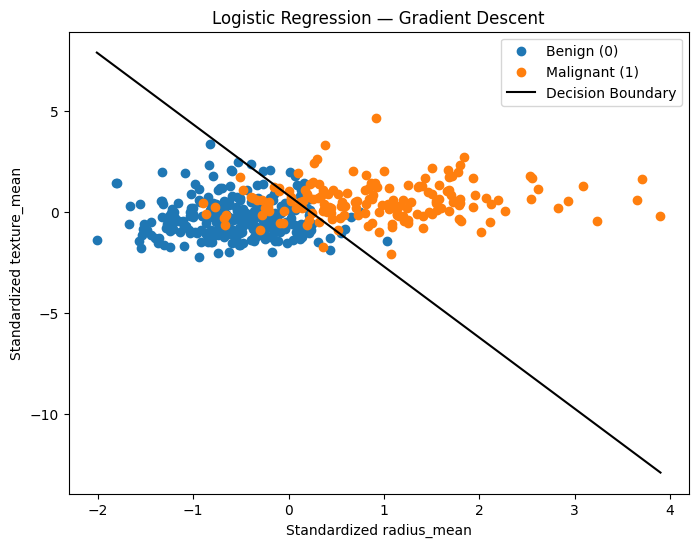

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_train[y_train == 0, 0],
    X_train[y_train == 0, 1],
    label="Benign (0)"
)

plt.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    label="Malignant (1)"
)

plt.plot(x_input, y_input, color="black", label="Decision Boundary")

plt.xlabel("Standardized radius_mean")
plt.ylabel("Standardized texture_mean")
plt.title("Logistic Regression — Gradient Descent")
plt.legend()
plt.show()

In [22]:
from sklearn.metrics import accuracy_score, classification_report

X_test_bias = np.insert(X_test, 0, 1, axis=1)
weights_full = np.insert(coef_, 0, intercept_)

y_prob = sigmoid(np.dot(X_test_bias, weights_full))
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.8596491228070176
              precision    recall  f1-score   support

           0       0.85      0.94      0.89        72
           1       0.88      0.71      0.79        42

    accuracy                           0.86       114
   macro avg       0.87      0.83      0.84       114
weighted avg       0.86      0.86      0.86       114

